In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


In [6]:

df = pd.read_csv("online_retail_II.csv", encoding="ISO-8859-1")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())



Dataset Shape: (525461, 8)

First 5 Records:
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

        InvoiceDate  Price  CustomerID         Country  
0  12-01-2009 07:45   6.95     13085.0  United Kingdom  
1  12-01-2009 07:45   6.75     13085.0  United Kingdom  
2  12-01-2009 07:45   6.75     13085.0  United Kingdom  
3  12-01-2009 07:45   2.10     13085.0  United Kingdom  
4  12-01-2009 07:45   1.25     13085.0  United Kingdom  


In [7]:
# Remove missing Customer IDs
df = df.dropna(subset=["CustomerID"])

# Remove cancelled transactions
df = df[~df["Invoice"].astype(str).str.startswith("C")]

# Remove invalid Quantity and UnitPrice
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

# Convert InvoiceDate into datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"],format="mixed",errors="coerce")

# Calculate total amount for each transaction
df["TotalAmount"] = df["Quantity"] * df["Price"]

print("\nDataset after preprocessing:", df.shape)


# Reference date
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)



Dataset after preprocessing: (407664, 9)


In [8]:

# Create RFM table
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "Invoice": "nunique",
    "TotalAmount": "sum"
})

# Rename columns
rfm.columns = [ "Recency", "Frequency", "Monetary"]

print("\nRFM Data:")
print(rfm.head())

print("\nRFM Statistics:")
print(rfm.describe())




RFM Data:
            Recency  Frequency  Monetary
CustomerID                              
12346.0         165         11    372.86
12347.0           3          2   1323.32
12348.0          74          1    222.16
12349.0          43          3   2671.14
12351.0          11          1    300.93

RFM Statistics:
           Recency    Frequency       Monetary
count  4312.000000  4312.000000    4312.000000
mean     91.171846     4.455705    2048.238236
std      96.860633     8.170213    8914.481280
min       1.000000     1.000000       2.950000
25%      18.000000     1.000000     307.987500
50%      53.000000     2.000000     706.020000
75%     136.000000     5.000000    1723.142500
max     374.000000   205.000000  349164.350000


In [9]:
# RFM data is generally skewed.
# Log transformation reduces the influence of extreme values.

rfm_log = np.log1p(rfm)

print("\nLog Transformed RFM:")
print(rfm_log.head())

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame( rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"], index=rfm.index)

print("\nStandardized RFM:")
print(rfm_scaled.head())




Log Transformed RFM:
             Recency  Frequency  Monetary
CustomerID                               
12346.0     5.111988   2.484907  5.923881
12347.0     1.386294   1.098612  7.188654
12348.0     4.317488   0.693147  5.407889
12349.0     3.784190   1.386294  7.890635
12351.0     2.484907   0.693147  5.710195

Standardized RFM:
             Recency  Frequency  Monetary
CustomerID                               
12346.0     0.966262   1.613017 -0.540688
12347.0    -1.900165  -0.394693  0.447651
12348.0     0.355000  -0.981910 -0.943904
12349.0    -0.055302   0.021945  0.996204
12351.0    -1.054928  -0.981910 -0.707671


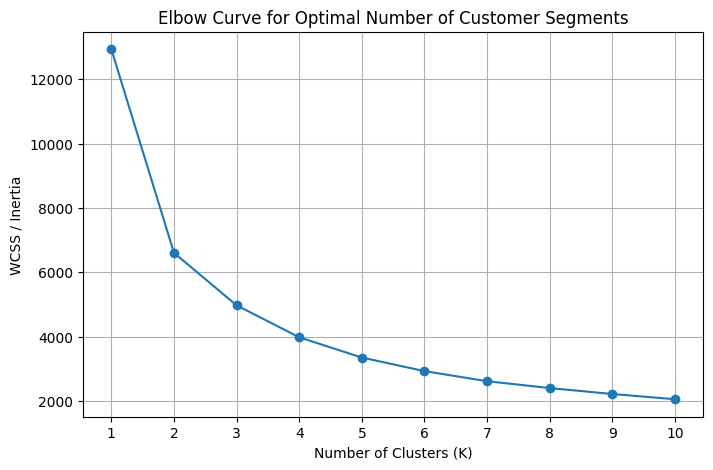

In [10]:
wcss = []

# Try K values from 1 to 10
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot( range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")

plt.title("Elbow Curve for Optimal Number of Customer Segments")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()




Customer Cluster Assignment:
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         165         11    372.86        3
12347.0           3          2   1323.32        0
12348.0          74          1    222.16        2
12349.0          43          3   2671.14        3
12351.0          11          1    300.93        0
12352.0          11          2    343.80        0
12353.0          44          1    317.76        0
12355.0         203          1    488.21        2
12356.0          16          3   3562.25        3
12357.0          24          2  12079.99        3
12358.0          11          3   2719.01        3
12359.0          61          6   2563.36        3
12360.0          15          5   1590.83        3
12361.0          98          3    321.35        2
12362.0         374          1    130.00        2
12366.0         269          1    500.24        2
12368.0         264          1    917.70        2
12369.0          49 

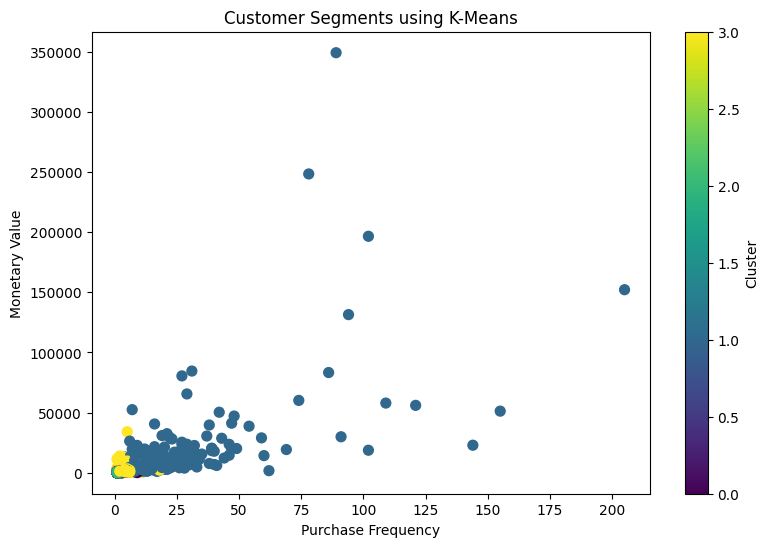

In [14]:
# Select K based on the elbow point.
# Example: K = 4

optimal_k = 4

kmeans = KMeans( n_clusters=optimal_k, random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("\nCustomer Cluster Assignment:")
print(rfm.head(20))

print("\nNumber of Customers in Each Segment:")
print(    rfm["Cluster"] .value_counts().sort_index())

cluster_profile = rfm.groupby("Cluster").agg({ "Recency": "mean", "Frequency": "mean",    "Monetary": "mean"}).round(2)

print("\nCustomer Segment Profile:")
print(cluster_profile)

plt.figure(figsize=(9, 6))
plt.scatter(rfm["Frequency"], rfm["Monetary"],  c=rfm["Cluster"], cmap="viridis",  s=50)
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value")
plt.title(    "Customer Segments using K-Means")
plt.colorbar(label="Cluster")
plt.show()